# Qestion 6: Gaussian Discriminant Analysis

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

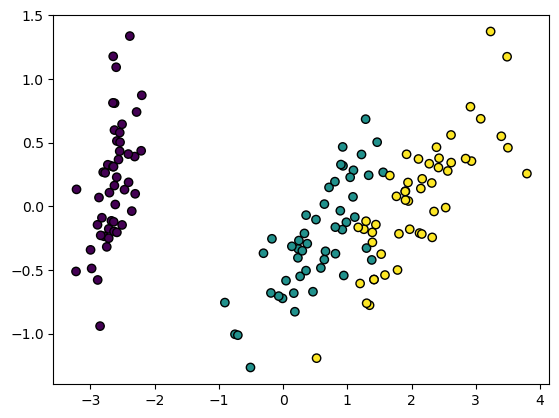

In [2]:
iris = datasets.load_iris()
Xorig = iris.data
y = iris.target
pca = PCA(n_components=2)
X = pca.fit(Xorig).transform(Xorig)
plt.scatter(X[:, 0], X[:, 1], marker='o', c=y, edgecolor='k')

## Part A

In [3]:
X_12 = X[(y == 1) | (y == 2)]
y_12 = y[(y == 1) | (y == 2)]

X_class1 = X[y==1]
X_class2 = X[y==2]

mean1 = np.mean(X_class1, axis=0)
mean2 = np.mean(X_class2, axis=0)

cov1 = np.cov(X_class1, rowvar=False)
cov2 = np.cov(X_class2, rowvar=False)

n1 = X_class1.shape[0]
n2 = X_class2.shape[0]
pooled = ((n1 - 1) * cov1 + (n2 - 1) * cov2) / (n1 + n2 - 2)

print('Mean Class 1: ', mean1)
print('Mean Class 2: ', mean2)
print('Shared Covariance: \n', pooled)

Mean Class 1:  [ 0.53320657 -0.24554983]
Mean Class 2:  [2.10920889 0.05466479]
Shared Covariance: 
 [[0.42688158 0.23729851]
 [0.23729851 0.20923235]]


## Part B

In [4]:
def discriminant_params(mu, sigma_inv, prior):
    # Linear discriminant: g_i(x) = w_i^T * x + w_i0
    # w_i = Sigma^-1 * mu_i
    # w_i0 = -0.5 * mu_i^T * Sigma^-1 * mu_i + log(P(w_i))
    w = np.dot(sigma_inv, mu)
    w0 = -0.5 * np.dot(mu.T, np.dot(sigma_inv, mu)) + np.log(prior)
    return w, w0

## Part C & D

In [5]:
Sigma_inv = np.linalg.inv(pooled)

w1, w1_0 = discriminant_params(mean1, Sigma_inv, 0.5)
w2, w2_0 = discriminant_params(mean2, Sigma_inv, 0.5)

# Decision Boundary equation is g1(x) = g2(x)
# so it will become (w1 - w2)^T * x + (w1_0 - w2_0) = 0
w_vec = w1 - w2
b_scalar = w1_0 - w2_0
# Line: w_vec[0]*x + w_vec[1]*y + b_scalar = 0
# y = -(w_vec[0]/w_vec[1])*x - (b_scalar/w_vec[1])
print(f'Line Equation: {w_vec[0]:.3}X + {w_vec[1]:.3}Y + {b_scalar:.3}')
print(f'Line Equation: Y = {-(w_vec[0] / w_vec[1]):.3}X + {-(b_scalar / w_vec[1]):.3}')

Line Equation: -7.83X + 7.45Y + 11.1
Line Equation: Y = 1.05X + -1.48


In [6]:
def plot_decision_boundary(X, y, w_vec, b_scalar, title):
    plt.figure(figsize=(8, 6))
    
    plt.scatter(X[y==1][:, 0], X[y==1][:, 1], color='blue', label='Class 1')
    plt.scatter(X[y==2][:, 0], X[y==2][:, 1], color='red', label='Class 2')
    
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.001),
                         np.arange(y_min, y_max, 0.001))
    
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    
    # Evaluate g1 - g2
    # g1 - g2 = w_vec^T * x + b
    val = np.dot(grid_points, w_vec) + b_scalar
    Z = val > 0 # Class 1 if > 0 else Class 2
    Z = Z.reshape(xx.shape)
    
    plt.contourf(xx, yy, Z, alpha=0.2, cmap=plt.cm.bwr)
    plt.contour(xx, yy, Z, colors='k', linewidths=1)
    
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title(title)
    plt.legend()
    plt.show()

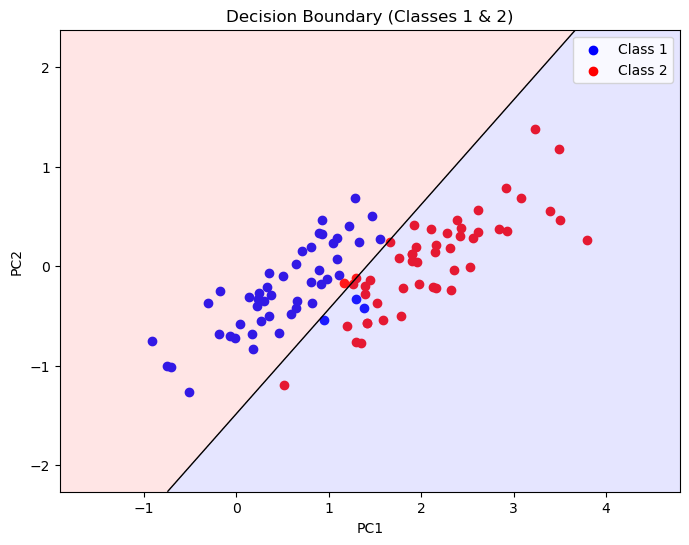

In [7]:
plot_decision_boundary(X_12, y_12, w_vec, b_scalar, 'Decision Boundary (Classes 1 & 2)')

## Part E

Line Equation: -7.83X + 7.45Y + 13.3
Line Equation: Y = 1.05X + -1.78


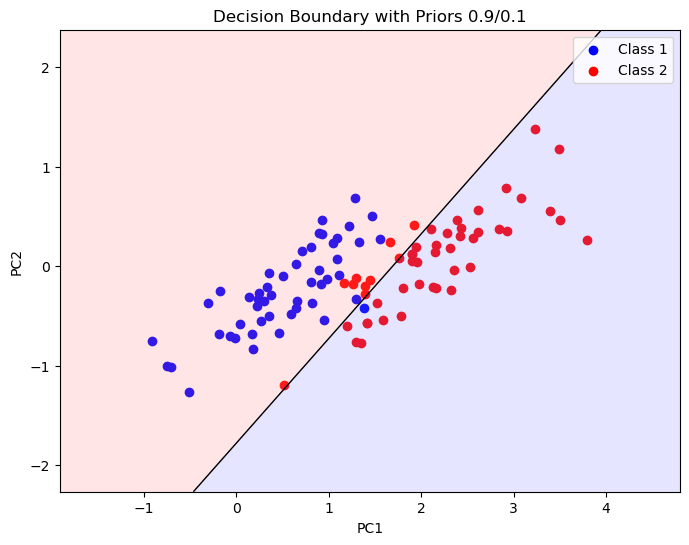

In [8]:
p1_new = 0.9
p2_new = 0.1
w1_new, w1_0_new = discriminant_params(mean1, Sigma_inv, p1_new)
w2_new, w2_0_new = discriminant_params(mean2, Sigma_inv, p2_new)
w_vec_new = w1_new - w2_new
b_scalar_new = w1_0_new - w2_0_new

print(f'Line Equation: {w_vec_new[0]:.3}X + {w_vec_new[1]:.3}Y + {b_scalar_new:.3}')
print(f'Line Equation: Y = {-(w_vec_new[0] / w_vec_new[1]):.3}X + {-(b_scalar_new / w_vec_new[1]):.3}')

plot_decision_boundary(X_12, y_12, w_vec_new, b_scalar_new, 'Decision Boundary with Priors 0.9/0.1')

## Part F

In [9]:
means = {}
covs = {}
cov_invs = {}
log_dets = {}
priors = {}

for c in [0, 1, 2]:
    X_c = X[y == c]
    means[c] = np.mean(X_c, axis=0)
    covs[c] = np.cov(X_c, rowvar=False)
    cov_invs[c] = np.linalg.inv(covs[c])
    log_dets[c] = np.log(np.linalg.det(covs[c]))
    priors[c] = 1/3

    print(f'Class {c}:')
    print(f'  Mean: {means[c]}')
    print(f'  Covariance Matrix:\n{covs[c]}')

Class 0:
  Mean: [-2.64241546  0.19088505]
  Covariance Matrix:
[[0.04902194 0.0560427 ]
 [0.0560427  0.2176973 ]]
Class 1:
  Mean: [ 0.53320657 -0.24554983]
  Covariance Matrix:
[[0.35547097 0.19874217]
 [0.19874217 0.18517223]]
Class 2:
  Mean: [2.10920889 0.05466479]
  Covariance Matrix:
[[0.49829218 0.27585486]
 [0.27585486 0.23329248]]


In [10]:
def multi_discriminant(x_vec, mu, sigma_inv, log_det, prior):
    diff = x_vec - mu
    quad = -0.5 * np.sum(np.dot(diff, sigma_inv) * diff, axis=1)
    const = -0.5 * log_det + np.log(prior)
    return quad + const

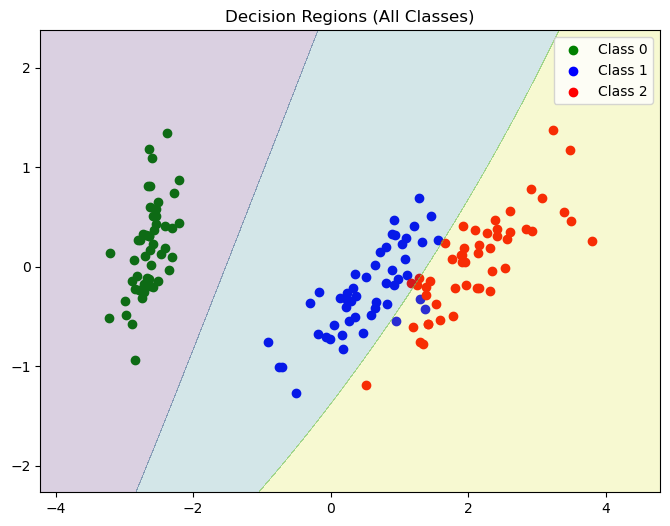

In [11]:
plt.figure(figsize=(8, 6))
colors = ['green', 'blue', 'red']
for c in [0, 1, 2]:
    plt.scatter(X[y==c][:, 0], X[y==c][:, 1], color=colors[c], label=f'Class {c}')

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.001),
                     np.arange(y_min, y_max, 0.001))
grid_points = np.c_[xx.ravel(), yy.ravel()]

scores = []
for c in [0, 1, 2]:
    s = multi_discriminant(grid_points, means[c], cov_invs[c], log_dets[c], priors[c])
    scores.append(s)
scores = np.array(scores)
predictions = np.argmax(scores, axis=0)
Z = predictions.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.2, cmap=plt.cm.viridis)
plt.title('Decision Regions (All Classes)')
plt.legend()
plt.show()

## Part I

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

means_tr = {}
covs_tr = {}
cov_invs_tr = {}
log_dets_tr = {}
priors_tr = {}

for c in [0, 1, 2]:
    X_c = X_train[y_train == c]
    means_tr[c] = np.mean(X_c, axis=0)
    covs_tr[c] = np.cov(X_c, rowvar=False)
    cov_invs_tr[c] = np.linalg.inv(covs_tr[c])
    log_dets_tr[c] = np.log(np.linalg.det(covs_tr[c]))
    priors_tr[c] = len(X_c) / len(X_train)

    print(f'Class {c}:')
    print(f'  Mean: {means_tr[c]}')
    print(f'  Covariance Matrix:\n{covs_tr[c]}')

Class 0:
  Mean: [-2.65211283  0.17923673]
  Covariance Matrix:
[[0.05467147 0.06187812]
 [0.06187812 0.24688109]]
Class 1:
  Mean: [ 0.51102344 -0.27979409]
  Covariance Matrix:
[[0.38801555 0.19792078]
 [0.19792078 0.17191438]]
Class 2:
  Mean: [2.17029556 0.10811734]
  Covariance Matrix:
[[0.56082818 0.29277294]
 [0.29277294 0.2345954 ]]


In [13]:
def get_posterior_probs(x_vec, classes, means, cov_invs, log_dets, priors):
    log_probs = []
    for c in classes:
        s = multi_discriminant(x_vec, means[c], cov_invs[c], log_dets[c], priors[c])
        log_probs.append(s)
    log_probs = np.array(log_probs)
    
    max_log = np.max(log_probs, axis=0)
    probs = np.exp(log_probs - max_log) #prevent overflow
    
    probs = probs / np.sum(probs, axis=0)
    return probs.T

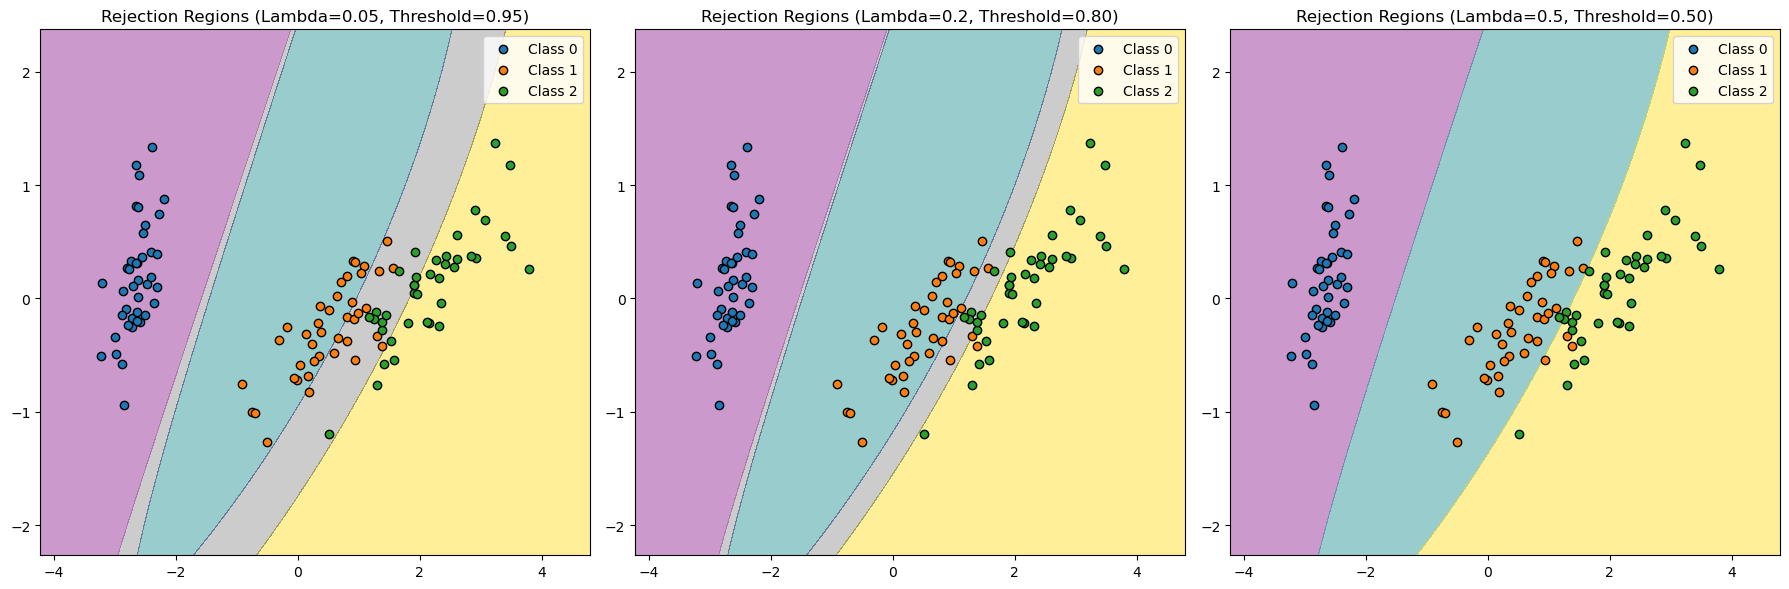

In [14]:
lambdas = [0.05, 0.2, 0.5]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, lam in enumerate(lambdas):
    threshold = 1 - lam

    probs = get_posterior_probs(grid_points, [0, 1, 2], means_tr, cov_invs_tr, log_dets_tr, priors_tr)
    max_probs = np.max(probs, axis=1)
    preds = np.argmax(probs, axis=1)

    final_preds = np.where(max_probs < threshold, -1, preds)  # class -1 for rejection
    Z = final_preds.reshape(xx.shape)

    axes[i].contourf(xx, yy, Z, levels=[-1.5, -0.5, 0.5, 1.5, 2.5], colors=['gray', 'purple', 'teal', 'gold'], alpha=0.4)

    for c in [0, 1, 2]:
        axes[i].scatter(X_train[y_train==c][:, 0], X_train[y_train==c][:, 1], label=f'Class {c}', edgecolor='k')

    axes[i].set_title(f"Rejection Regions (Lambda={lam}, Threshold={threshold:.2f})")
    axes[i].legend()

plt.tight_layout()
plt.show()

# Question 7

In [18]:
import scipy.io
import numpy as np

In [19]:
mat_data = scipy.io.loadmat('./data/guassianBayes.mat')
print(mat_data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'yTest', 'xTrain', 'xTest', 'yTrain'])


In [20]:
X_train = mat_data['xTrain']
y_train = mat_data['yTrain'].flatten()
X_test = mat_data['xTest']
y_test = mat_data['yTest'].flatten()
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((218, 5), (218,), (109, 5), (109,))

## Part A

In [21]:
def prior(y_train):
    classes = np.unique(y_train)
    num_classes = len(classes)
    
    priors = np.zeros(num_classes)
    for idx, c in enumerate(classes):
        priors[idx] = np.mean(y_train == c)
        
    return priors

In [22]:
prior(y_train)

array([0.47247706, 0.23394495, 0.14220183, 0.10091743, 0.05045872])

## Part B

In [23]:
def likelihood(X_train, y_train):

    classes = np.unique(y_train)
    num_classes = len(classes)
    num_features = X_train.shape[1]

    M = np.zeros((num_features, num_classes))
    V = np.zeros((num_features, num_classes))
    
    for idx, c in enumerate(classes):
        X_c = X_train[y_train == c]
        M[:, idx] = np.mean(X_c, axis=0)
        V[:, idx] = np.var(X_c, axis=0)

    return M, V

In [24]:
likelihood(X_train, y_train)

(array([[0.35941748, 0.47176471, 0.65129032, 0.73909091, 0.68909091],
        [0.40728155, 0.5054902 , 0.71580645, 0.47045455, 0.69      ],
        [0.45339806, 0.52686275, 0.43032258, 0.58136364, 0.76727273],
        [0.30796117, 0.7554902 , 0.47      , 0.74909091, 0.48181818],
        [0.39300971, 0.71019608, 0.38709677, 0.76909091, 0.31545455]]),
 array([[0.01513558, 0.04263414, 0.01081769, 0.01084463, 0.00419008],
        [0.00763533, 0.00782868, 0.02135338, 0.00950434, 0.01081818],
        [0.00902243, 0.01632741, 0.00637086, 0.00393905, 0.0042562 ],
        [0.00907254, 0.01229535, 0.01243871, 0.00563554, 0.00665124],
        [0.00896861, 0.03632741, 0.01572383, 0.00478099, 0.01077025]]))

## Part C

In [25]:
def naiveBayesClassify(X_test, M, V, p):
    classes = np.unique(y_train)
    y_pred = []
    for i in range(X_test.shape[0]):
        x = X_test[i, :]
        scores = []
        for idx, _ in enumerate(classes):
            mu = M[:, idx]
            var = V[:, idx]
            prior = p[idx]
            
            log_prior = np.log(prior)
            
            # Log likelihood components
            # term1 = -0.5 * log(var)
            # term2 = - (x - mu)^2 / (2 * var)
            # adding or removing constant (-1/2 ln(2*pi)) doesn't change argmax, so it won't be added
            
            
            term1 = -0.5 * np.log(var + 1e-9) 
            term2 = -0.5 * ((x - mu)**2) / (var + 1e-9)
            
            log_likelihood = np.sum(term1 + term2)
            scores.append(log_likelihood + log_prior)
        
        y_pred.append(classes[np.argmax(scores)])
    
    return np.array(y_pred)

In [26]:
M, V = likelihood(X_train, y_train)
p = prior(y_train)
y_pred = naiveBayesClassify(X_test, M, V, p)
y_pred

array([3, 5, 2, 4, 1, 1, 2, 2, 1, 5, 1, 1, 1, 3, 1, 3, 1, 1, 1, 4, 4, 3,
       1, 3, 3, 2, 1, 3, 1, 1, 2, 2, 2, 1, 1, 4, 1, 1, 5, 2, 2, 1, 1, 1,
       1, 3, 2, 1, 5, 3, 4, 4, 2, 1, 3, 1, 4, 3, 4, 4, 2, 3, 2, 5, 4, 4,
       4, 5, 5, 1, 1, 2, 3, 3, 4, 4, 1, 5, 4, 3, 3, 2, 1, 1, 2, 3, 3, 1,
       2, 4, 2, 1, 1, 3, 1, 1, 3, 2, 1, 2, 1, 3, 2, 1, 1, 4, 4, 1, 1],
      dtype=int64)

## Part D

In [27]:
def precision_and_recall_of_class(cls, y_true, y_pred):
        tp = np.sum((y_pred == cls) & (y_true == cls))
        fp = np.sum((y_pred == cls) & (y_true != cls))
        fn = np.sum((y_pred != cls) & (y_true == cls))
        
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0
        return prec, rec

In [28]:
accuracy = np.mean(y_pred == y_test)
prec1, rec1 = precision_and_recall_of_class(1, y_test, y_pred)
prec5, rec5 = precision_and_recall_of_class(5, y_test, y_pred)
print(f'Accuracy: {accuracy:.3f}')
print(f'Class 1 Precision: {prec1:.3f}, Recall: {rec1:.3f}')
print(f'Class 5 Precision: {prec5:.3f}, Recall: {rec5:.3f}')

Accuracy: 0.835
Class 1 Precision: 0.951, Recall: 0.975
Class 5 Precision: 0.875, Recall: 0.778


# Question 8

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [31]:
baseball_train = pd.read_csv('./data/baseball_train_set.csv', header=None).values
baseball_test = pd.read_csv('./data/baseball_test_set.csv', header=None).values
hockey_train = pd.read_csv('./data/hockey_train_set.csv', header=None).values
hockey_test = pd.read_csv('./data/hockey_test_set.csv', header=None).values
vocab = pd.read_csv('./data/vocabulary.txt', header=None).values

print('Baseball Train Shape:', baseball_train.shape)
print('Hockey Train Shape:', hockey_train.shape)
print('Vocab Shape:', vocab.shape)

Baseball Train Shape: (50, 5822)
Hockey Train Shape: (50, 5822)
Vocab Shape: (5822, 1)


## Part A

In [32]:
def predict_naive_bayes_mle(baseball_train, hockey_train, X_test, prior_bb=0.5, prior_hk=0.5):
    count_w_baseball = np.sum(baseball_train, axis=0)
    count_w_hockey = np.sum(hockey_train, axis=0)
    
    total_words_baseball = np.sum(count_w_baseball)
    total_words_hockey = np.sum(count_w_hockey)
    
    p_w_baseball = count_w_baseball / total_words_baseball
    p_w_hockey = count_w_hockey / total_words_hockey
    
    preds = []
    for x in X_test:
        score_baseball = np.log(prior_bb)
        mask_bb = (x > 0)
        if np.any(p_w_baseball[mask_bb] == 0):
            score_baseball = -np.inf
        else:
            score_baseball += np.sum(x[mask_bb] * np.log(p_w_baseball[mask_bb]))
        
        score_hockey = np.log(prior_hk)
        mask_hk = (x > 0)
        if np.any(p_w_hockey[mask_hk] == 0):
            score_hockey = -np.inf
        else:
            score_hockey += np.sum(x[mask_hk] * np.log(p_w_hockey[mask_hk]))


        if score_baseball >= score_hockey:
            preds.append(0)
        else:
            preds.append(1)
    
    return np.array(preds)


In [33]:
X_test = np.vstack([baseball_test, hockey_test])
y_test = np.array([0]*50 + [1]*50)
preds_mle = predict_naive_bayes_mle(baseball_train, hockey_train, X_test)
acc_mle = np.mean(preds_mle == y_test)
print(f'MLE Accuracy: {acc_mle:.3f}')

MLE Accuracy: 0.500


In [34]:
preds_mle

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

## Part B

In [35]:
def train_map(X_baseball, X_hockey, beta):
    vocab_size = X_baseball.shape[1]
    
    c_w_baseball = np.sum(X_baseball, axis=0)
    c_w_hockey = np.sum(X_hockey, axis=0)
    
    # Denominator: sum of (count + beta) over all words = sum(count) + beta * vocab_size
    denom_baseball = np.sum(c_w_baseball) + beta * vocab_size
    denom_hockey = np.sum(c_w_hockey) + beta * vocab_size
    
    p_baseball = (c_w_baseball + beta) / denom_baseball
    p_hockey = (c_w_hockey + beta) / denom_hockey
    
    return p_baseball, p_hockey

## Part C

In [36]:
def predict_map(X, p_baseball, p_hockey):
    epsilon = 1e-20
    log_p_baseball = np.log(p_baseball + epsilon)
    log_p_hockey = np.log(p_hockey + epsilon)
    
    scores_bb = X @ log_p_baseball
    scores_hk = X @ log_p_hockey

    return np.where(scores_bb >= scores_hk, 0, 1)


Accuracies per Beta:
Beta 0: 0.860
Beta 1e-08: 0.870
Beta 1e-06: 0.860
Beta 0.001: 0.860
Beta 0.01: 0.870
Beta 0.1: 0.870
Beta 1: 0.790
Beta 2: 0.650
Beta 5: 0.550
Beta 10: 0.540


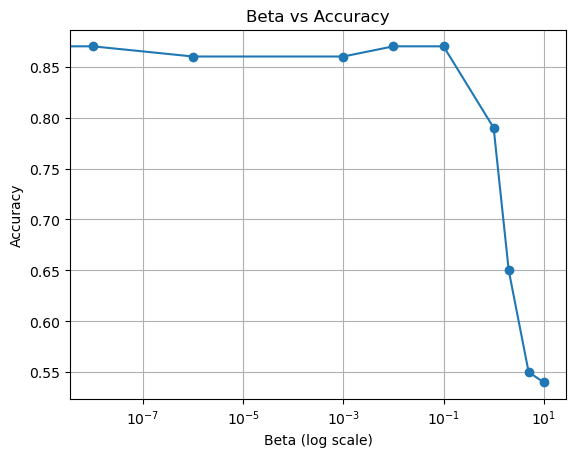

In [37]:
betas = [0, 1e-8, 1e-6, 1e-3, 1e-2, 1e-1, 1, 2, 5, 10]
accuracies_beta = []

for b in betas:
    p_baseball, p_hockey = train_map(baseball_train, hockey_train, b)
    preds = predict_map(X_test, p_baseball, p_hockey)
    acc = np.mean(preds == y_test)
    accuracies_beta.append(acc)
    
plt.figure()
plt.semilogx(betas, accuracies_beta, marker='o')
plt.title('Beta vs Accuracy')
plt.xlabel('Beta (log scale)')
plt.ylabel('Accuracy')
plt.grid(True)

print("Accuracies per Beta:")
for b, acc in zip(betas, accuracies_beta):
    print(f"Beta {b}: {acc:.3f}")

## Part D

Accuracies per N:
N 1: 0.460
N 5: 0.590
N 10: 0.750
N 15: 0.600
N 20: 0.710
N 25: 0.810
N 30: 0.810
N 35: 0.830
N 40: 0.840
N 45: 0.880
N 50: 0.870


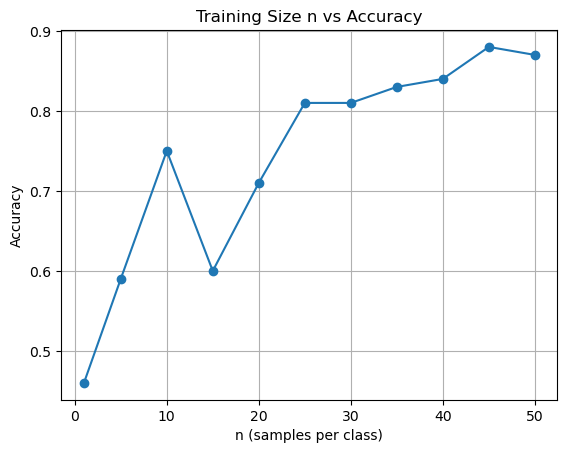

In [38]:
ns = [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
accuracies_n = []
beta = 0.1

for n in ns:
    sub_baseball = baseball_train[:n, :]
    sub_hockey = hockey_train[:n, :]
    
    p_baseballb, p_hockey = train_map(sub_baseball, sub_hockey, beta)
    preds = predict_map(X_test, p_baseballb, p_hockey)
    acc = np.mean(preds == y_test)
    accuracies_n.append(acc)

plt.figure()
plt.plot(ns, accuracies_n, marker='o')
plt.title('Training Size n vs Accuracy')
plt.xlabel('n (samples per class)')
plt.ylabel('Accuracy')
plt.grid(True)

print("Accuracies per N:")
for n, acc in zip(ns, accuracies_n):
    print(f"N {n}: {acc:.3f}")